<a href="https://colab.research.google.com/github/rabicenkonikita3-cloud/python-practice-algos/blob/master/hw-5-rabichencko_mnist_14.10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Train: (54000, 784), Val: (6000, 784), Test: (10000, 784)



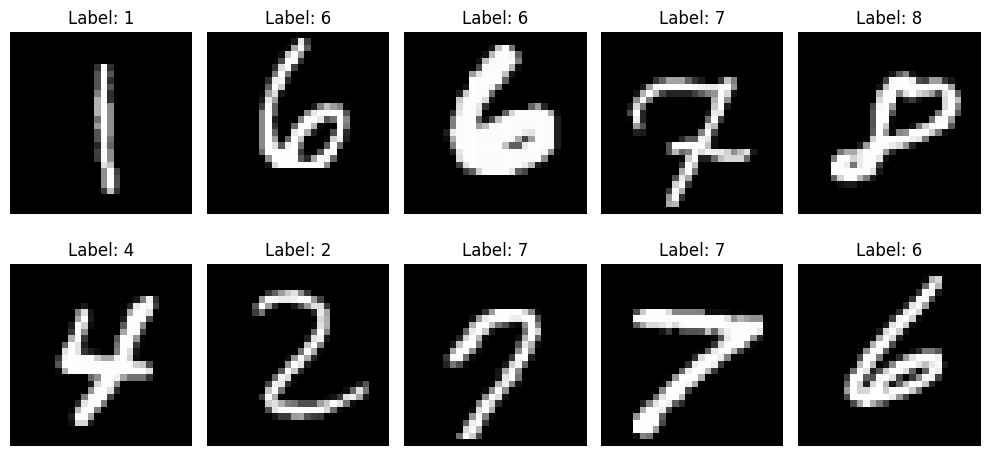

Decision Tree: train=1.000, val=0.871
Random Forest: train=1.000, val=0.971
Decision Tree test accuracy: 0.874
Random Forest test accuracy:  0.967
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.95      0.96      0.96      1032
           3       0.95      0.96      0.96      1010
           4       0.97      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.97      0.97      0.97       958
           7       0.97      0.96      0.97      1028
           8       0.96      0.95      0.95       974
           9       0.96      0.94      0.95      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



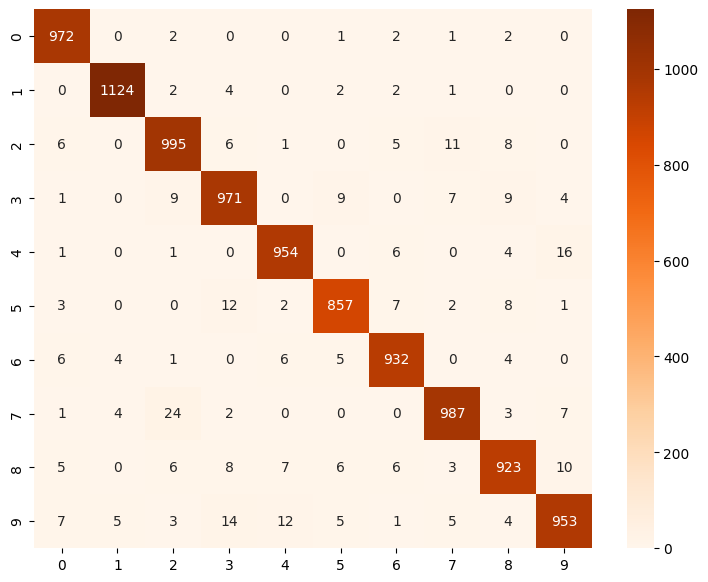

In [ ]:
import os
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
skachano =kagglehub.dataset_download("hojjatk/mnist-dataset")

if "train-images.idx3-ubyte" not in os.listdir(skachano):
    for root, dirs, files in os.walk(skachano):
        if "train-images.idx3-ubyte" in files:
            path=root
            break
else:
    path= skachano

def chitay_x(fail):
    with open(fail,'rb') as f:
        f.read(16)
        return np.fromfile(f,dtype=np.uint8).reshape(-1,784 )
def chitay_y(fail):
    with open(fail,'rb' ) as f:
        f.read(8)
        return np.fromfile(f,dtype=np.uint8)
f_x_train = os.path.join(path, "train-images.idx3-ubyte")
f_y_train =os.path.join(path, "train-labels.idx1-ubyte")
f_x_test = os.path.join(path, "t10k-images.idx3-ubyte")
f_y_test= os.path.join(path,"t10k-labels.idx1-ubyte")
x_all = chitay_x(f_x_train)
y_all =chitay_y(f_y_train)
x_test =chitay_x(f_x_test )
y_test = chitay_y( f_y_test)
x_train,x_val,y_train, y_val =train_test_split(x_all, y_all,test_size=0.1,random_state=42 )
print(f"Train: {x_train.shape}, Val: {x_val.shape}, Test: {x_test.shape}")
print()

fig,axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()
derevo = DecisionTreeClassifier(random_state=42)
derevo.fit(x_train, y_train)
print(f"Decision Tree: train={accuracy_score(y_train, derevo.predict(x_train)):.3f}, val={accuracy_score(y_val, derevo.predict(x_val)):.3f}" )
les = RandomForestClassifier(n_estimators=50,random_state=42,n_jobs=-1)
les.fit(x_train,y_train)
print(f"Random Forest: train={accuracy_score(y_train, les.predict(x_train)):.3f}, val={accuracy_score(y_val, les.predict(x_val)):.3f}")
pred_dereva =derevo.predict(x_test)
pred_lesa = les.predict(x_test)
print(f"Decision Tree test accuracy:{accuracy_score(y_test, pred_dereva):.3f}")
print(f"Random Forest test accuracy:  {accuracy_score(y_test, pred_lesa):.3f}")
print(classification_report(y_test, pred_lesa))
matrica = confusion_matrix(y_test,pred_lesa)
plt.figure(figsize=(9,7))
sns.heatmap(matrica, annot=True, fmt='d', cmap='Oranges')
plt.show()
